In [33]:
from __future__ import annotations

import json
import os
import re
from typing import Any, TypedDict

import pandas as pd
import requests
from dotenv import load_dotenv
from langchain_groq import ChatGroq
from langchain_tavily import TavilySearch
from langgraph.graph import END, START, StateGraph
from pydantic import BaseModel, Field, ValidationError
from langchain_core.messages import SystemMessage, HumanMessage

In [18]:
load_dotenv()

NASA_POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"
NASA_PARAMETERS = ["T2M", "T2M_MAX", "T2M_MIN", "PRECTOTCORR"]
NASA_COMMUNITY = "AG"

START_DATE = os.getenv("NASA_START_DATE", "20250101")
END_DATE = os.getenv("NASA_END_DATE", "20251231")

GROQ_API_KEY = os.getenv("GROQ_API_KEY")
TAVILY_API_KEY = os.getenv("TAVILY_API_KEY")
GROQ_MODEL = os.getenv("GROQ_MODEL", "openai/gpt-oss-20b")

In [19]:
# Demo profile. Replace these values with the farmer's actual profile.
FARM_DATA = {
    "farmName": "Demo Farm",
    "location": "Damanhur, Beheira, Egypt",
    "latitude": 31.04,
    "longitude": 30.47,
    "cultivatedArea": 5.0,
    "areaUnit": "Acres",
    "soilType": "Sandy loam",
    "soilPH": 7.5,
    "soilSalinityEC": 1.2,
    "soilOrganicMatter": 1.8,
    "currentCrop": "Maize",
    "previousWinterCrop": "Wheat",
    "cropHistory": [
        {"crop": "Wheat", "season": "Winter", "year": 2024},
        {"crop": "Maize", "season": "Summer", "year": 2024},
        {"crop": "Wheat", "season": "Winter", "year": 2025},
        {"crop": "Maize", "season": "Summer", "year": 2025},
    ],
    "plantingDate": "2026-05-01",
    "expectedHarvestDate": "2026-09-15",
    "waterSource": "Nile irrigation canal",
    "irrigationMethod": "Surface irrigation",
    "irrigationFrequency": "Every 10 days",
    "availableWaterAmount": 3000,
    "availableWaterUnit": "m3 per acre per season",
    "farmerGoal": [
        "Improve soil health",
        "Maintain crop productivity",
        "Reduce water consumption",
    ],
    "goalPriority": [
        "Improve soil health",
        "Maintain crop productivity",
        "Reduce water consumption",
    ],
}

In [20]:
# ============================================================
# 2. STRUCTURED OUTPUT MODELS
# ============================================================

class EvidenceItem(BaseModel):
    title: str
    url: str = ""
    year: str = "Not stated"
    region: str = "Not stated"
    evidence_type: str = "Not classified"
    relevant_findings: str
    limitations: str = "Not stated"
    relevance: str = Field(description="High, medium, or low")


class EvidenceReview(BaseModel):
    evidence: list[EvidenceItem]


class RotationStrategy(BaseModel):
    name: str
    crop_sequence: list[str]
    seasons: list[str]
    rationale: str
    expected_benefits: list[str]
    risks_and_uncertainties: list[str]
    evidence_used: list[str]


class StrategyOutput(BaseModel):
    strategies: list[RotationStrategy]
    overall_notes: list[str]

In [21]:
# ============================================================
# 3. SHARED STATE
# ============================================================

class FieldShiftState(TypedDict, total=False):
    farm: dict[str, Any]
    climate_data: list[dict[str, Any]]
    climate_summary: dict[str, Any]
    research_results: list[dict[str, Any]]
    evidence_review: dict[str, Any]
    strategy_output: dict[str, Any]
    validation: dict[str, Any]
    error: str

In [ ]:
# ============================================================
# 4. HELPERS
# ============================================================

def require_api_keys() -> None:
    missing = []
    if not GROQ_API_KEY:
        missing.append("GROQ_API_KEY")
    if not TAVILY_API_KEY:
        missing.append("TAVILY_API_KEY")
    if missing:
        raise RuntimeError(
            "Missing API key(s): "
            + ", ".join(missing)
            + ". Add them to the .env file. See README."
        )





def get_llm() -> ChatGroq:
    return ChatGroq(
        model=GROQ_MODEL,
        temperature=0.2,
        api_key=GROQ_API_KEY,
    )


def content_to_text(response: Any) -> str:
    """Extract text from a LangChain AIMessage or plain string."""
    content = getattr(response, "content", response)
    if isinstance(content, str):
        return content
    if isinstance(content, list):
        parts = []
        for item in content:
            if isinstance(item, dict) and item.get("type") == "text":
                parts.append(item.get("text", ""))
            elif isinstance(item, str):
                parts.append(item)
        return "\n".join(parts)
    return str(content)


def parse_json_response(response: Any) -> dict[str, Any]:
    """Parse JSON even if the model wraps it in Markdown fences."""
    text = content_to_text(response).strip()
    text = re.sub(r"^```(?:json)?\s*", "", text, flags=re.IGNORECASE)
    text = re.sub(r"\s*```$", "", text)
    start = text.find("{")
    end = text.rfind("}")
    if start == -1 or end == -1 or end < start:
        raise ValueError(
            "The model did not return a JSON object. "
            "Try again or choose another GROQ_MODEL."
        )
    candidate = text[start:end + 1]
    try:
        return json.loads(candidate)
    except json.JSONDecodeError:
        # Repair common LLM mistakes: trailing commas and literal
        # newlines inside string values.
        repaired = re.sub(r",\s*([}\]])", r"\1", candidate)
        repaired = repaired.replace("\r", " ").replace("\n", " ")
        return json.loads(repaired)



def llm_json_call(llm: Any, prompt: str, attempts: int = 3) -> dict[str, Any]:
    """
    Invoke the LLM, inspect its response, and retry with correction
    instructions if the returned JSON is invalid.
    """

    current_prompt = prompt
    last_error = None

    for attempt in range(1, attempts + 1):

        print(f"\nLLM request attempt: {attempt}/{attempts}")

        response = llm.invoke(current_prompt)

        raw_text = content_to_text(response).strip()

        try:
            result = parse_json_response(raw_text)

            print("Valid JSON received.")
            return result

        except (ValueError, json.JSONDecodeError) as exc:

            last_error = exc

            print("\nJSON PARSING FAILED")
            print("Error:", str(exc))

            print("\nRAW MODEL RESPONSE:")
            print(repr(raw_text))

            print("\nRESPONSE METADATA:")
            print(response.response_metadata)

            if attempt < attempts:

                current_prompt = f"""
Your previous response was invalid JSON.

The parsing error was:
{str(exc)}

Your previous response was:
{raw_text}

Please correct the JSON syntax and return the corrected
JSON object only.

Important:
- Preserve the original information.
- Do not remove required fields.
- Do not add explanations.
- Return valid JSON only.

Original task:
{prompt}
"""

    raise ValueError(
        f"LLM failed to return valid JSON after {attempts} attempts. "
        f"Last error: {last_error}"
    )



In [23]:
# ============================================================
# 5. NODE 1 - GET NASA POWER HISTORICAL DATA
# ============================================================

def get_nasa_data(
    latitude: float,
    longitude: float,
    start_date: str,
    end_date: str,
) -> pd.DataFrame:
    params = {
        "parameters": ",".join(NASA_PARAMETERS),
        "community": NASA_COMMUNITY,
        "longitude": longitude,
        "latitude": latitude,
        "start": start_date,
        "end": end_date,
        "format": "JSON",
        "time-standard": "UTC",
    }

    response = requests.get(NASA_POWER_URL, params=params, timeout=90)
    response.raise_for_status()
    payload = response.json()

    try:
        parameter_data = payload["properties"]["parameter"]
    except KeyError as exc:
        raise ValueError(
            "Unexpected NASA POWER response: 'properties.parameter' was not found."
        ) from exc

    df = pd.DataFrame(parameter_data)
    df.index = pd.to_datetime(df.index, format="%Y%m%d", errors="coerce")
    df.index.name = "date"
    df = df.reset_index()

    for column in NASA_PARAMETERS:
        if column not in df.columns:
            raise ValueError(f"NASA POWER response is missing {column}.")

    df[NASA_PARAMETERS] = df[NASA_PARAMETERS].apply(
        pd.to_numeric, errors="coerce"
    )
    df[NASA_PARAMETERS] = df[NASA_PARAMETERS].replace(-999, float("nan"))
    df = df.dropna(subset=["date"])

    if df[NASA_PARAMETERS].notna().sum().sum() == 0:
        raise ValueError(
            "NASA POWER returned no valid values for the requested parameters "
            "and dates. Check the response and date range before continuing."
        )

    return df


def nasa_collection_node(state: FieldShiftState) -> dict[str, Any]:
    farm = state["farm"]
    print("\n[1/6] Downloading historical climate data from NASA POWER...")

    df = get_nasa_data(
        latitude=float(farm["latitude"]),
        longitude=float(farm["longitude"]),
        start_date=START_DATE,
        end_date=END_DATE,
    )

    records = df.assign(
        date=df["date"].dt.strftime("%Y-%m-%d")
    ).to_dict(orient="records")

    print(f"Downloaded {len(records)} daily records.")
    return {"climate_data": records}

In [24]:

# ============================================================
# 6. NODE 2 - ANALYZE CLIMATE DATA
# ============================================================

def analyze_climate_node(state: FieldShiftState) -> dict[str, Any]:
    print("\n[2/6] Analyzing climate data...")

    df = pd.DataFrame(state["climate_data"])
    df["date"] = pd.to_datetime(df["date"])

    summary: dict[str, Any] = {
        "period": f"{START_DATE} to {END_DATE}",
        "valid_daily_records": int(len(df)),
        "missing_values": {},
        "annual": {},
        "monthly": [],
    }

    for column in NASA_PARAMETERS:
        summary["missing_values"][column] = int(df[column].isna().sum())

    if "T2M" in df:
        summary["annual"]["average_temperature_c"] = round(
            float(df["T2M"].mean()), 2
        ) if df["T2M"].notna().any() else None

    if "T2M_MAX" in df:
        summary["annual"]["highest_daily_max_temperature_c"] = round(
            float(df["T2M_MAX"].max()), 2
        ) if df["T2M_MAX"].notna().any() else None

    if "T2M_MIN" in df:
        summary["annual"]["lowest_daily_min_temperature_c"] = round(
            float(df["T2M_MIN"].min()), 2
        ) if df["T2M_MIN"].notna().any() else None

    if "PRECTOTCORR" in df:
        summary["annual"]["total_precipitation_mm"] = round(
            float(df["PRECTOTCORR"].sum()), 2
        ) if df["PRECTOTCORR"].notna().any() else None

    df["month"] = df["date"].dt.month
    monthly = df.groupby("month").agg(
        mean_temperature_c=("T2M", "mean"),
        precipitation_mm=("PRECTOTCORR", "sum"),
        mean_daily_max_temperature_c=("T2M_MAX", "mean"),
        mean_daily_min_temperature_c=("T2M_MIN", "mean"),
    ).reset_index()

    summary["monthly"] = monthly.round(2).where(
        pd.notna(monthly), None
    ).to_dict(orient="records")

    print(json.dumps(summary["annual"], indent=2))
    return {"climate_summary": summary}


In [25]:
# ============================================================
# 7. NODE 3 - AGRICULTURAL RESEARCH WITH TAVILY
# ============================================================

def condense_research_result(llm: Any, item: dict[str, Any]) -> dict[str, Any]:
    """Use the LLM to reduce a search result to its key points only."""
    prompt = (
        "You are condensing a web search result about agricultural research "
        "on crop rotation for a farm decision-support system.\n\n"
        f"Title: {item['title']}\n"
        f"URL: {item['url']}\n"
        f"Content:\n{item['content']}\n\n"
        "Extract ONLY the most important points relevant to crop rotation, "
        "soil health, water use, or seasonal crop suitability. Return a "
        "JSON object in this exact format:\n"
        '{"key_points": ["point 1", "point 2"], "summary": "one short sentence"}.\n'
        "Use at most 5 short key points. Ignore navigation text, ads, and "
        "boilerplate. Return JSON only."
    )
    try:
        raw = parse_json_response(llm.invoke(prompt))
        key_points = [
            str(point).strip()
            for point in raw.get("key_points", [])
            if str(point).strip()
        ][:5]
        summary = str(raw.get("summary", "")).strip()
    except Exception:
        key_points = []
        summary = ""

    condensed = {
        "title": item["title"],
        "url": item["url"],
        "score": item.get("score"),
    }
    if key_points:
        condensed["key_points"] = key_points
        if summary:
            condensed["summary"] = summary
    else:
        condensed["content"] = item["content"][:400]
    return condensed


def research_node(state: FieldShiftState) -> dict[str, Any]:
    print("\n[3/6] Searching for agricultural research with Tavily...")

    farm = state["farm"]
    climate = state["climate_summary"]

    query = (
        f"Scientific studies and agricultural extension research about crop "
        f"rotation suitable for {farm['location']}, Egypt, under conditions "
        f"similar to {farm['soilType']} soil. Consider crop rotation after "
        f"{farm['currentCrop']}, soil organic matter, salinity, irrigation "
        f"water limitations, heat and rainfall patterns. Prioritize Egypt, "
        f"Nile Delta, and Mediterranean climate studies. Find evidence about "
        f"seasonal suitability, soil health, legumes, crop water requirements, "
        f"and rotation constraints. Climate summary: "
        f"{json.dumps(climate['annual'])}"
    )

    search_tool = TavilySearch(
        max_results=6,
        search_depth="basic",
        topic="general",
        include_answer=False,
        include_raw_content=False,
    )

    result = search_tool.invoke({"query": query})

    if isinstance(result, dict):
        results = result.get("results", [])
    elif isinstance(result, list):
        results = result
    else:
        results = []

    cleaned = []
    for item in results:
        if not isinstance(item, dict):
            continue
        cleaned.append({
            "title": item.get("title", "Untitled"),
            "url": item.get("url", ""),
            "content": (item.get("content") or "")[:1800],
            "score": item.get("score"),
        })

    if not cleaned:
        raise ValueError(
            "Tavily returned no search results. Check TAVILY_API_KEY "
            "and try again."
        )

    print(f"Found {len(cleaned)} search results. Condensing to key points...")
    llm = get_llm()
    condensed = [condense_research_result(llm, item) for item in cleaned]

    print(f"Condensed {len(condensed)} results.")
    return {"research_results": condensed}

In [26]:
# ============================================================
# 8. NODE 4 - SCREEN THE RESEARCH EVIDENCE
# ============================================================

def evidence_evaluation_node(state: FieldShiftState) -> dict[str, Any]:
    print("\n[4/6] Evaluating the research evidence...")

    llm = get_llm()
    prompt = f"""
You are reviewing agricultural research for a decision-support prototype.

Farm profile:
{json.dumps(state['farm'], ensure_ascii=False, indent=2)}

NASA POWER historical climate summary:
{json.dumps(state['climate_summary'], ensure_ascii=False, indent=2)}

Search results:
{json.dumps(state['research_results'], ensure_ascii=False, indent=2)}

Task:
1. Screen each source for relevance and credibility based only on the supplied text.
2. Do not invent study years, locations, results, crop coefficients, or measurements.
3. If a field is not stated, write "Not stated".
4. Distinguish experimental studies, reviews, official guidance, and other sources.
5. Extract only findings actually supported by the supplied search-result text.
6. Keep limitations and uncertainty explicit.
7. Return valid JSON only, with this exact top-level structure:
{{
  "evidence": [
    {{
      "title": "...",
      "url": "...",
      "year": "...",
      "region": "...",
      "evidence_type": "...",
      "relevant_findings": "...",
      "limitations": "...",
      "relevance": "high|medium|low"
    }}
  ]
}}
"""

    raw = llm_json_call(llm, prompt)
    validated = EvidenceReview.model_validate(raw)
    result = validated.model_dump()

    print(f"Reviewed {len(result['evidence'])} sources.")
    return {"evidence_review": result}

In [27]:
# ============================================================
# 9. NODE 5 - GENERATE CROP ROTATION STRATEGIES
# ============================================================

def strategy_generation_node(state: FieldShiftState) -> dict[str, Any]:
    print("\n[5/6] Generating crop-rotation strategies...")

    llm = get_llm()
    prompt = f"""
You are an agricultural decision-support assistant.
Generate exactly THREE meaningfully different crop-rotation strategies.

Farm profile:
{json.dumps(state['farm'], ensure_ascii=False, indent=2)}

NASA POWER historical climate analysis:
{json.dumps(state['climate_summary'], ensure_ascii=False, indent=2)}

Screened agricultural evidence:
{json.dumps(state['evidence_review'], ensure_ascii=False, indent=2)}

Rules:
- Use the farm's crop history and current crop.
- Consider local seasonal calendars and the stated soil and irrigation context.
- Do not simply repeat the same sequence with different names.
- Do not assume a crop is suitable unless the supplied evidence or sound,
  clearly qualified agronomic reasoning supports considering it.
- If local evidence is weak, explicitly say so and identify what needs local
  agronomist verification.
- Do not invent yield increases, water-saving percentages, financial returns,
  or numerical soil improvements.
- Do not claim NASA POWER directly measures soil health or crop water use.
- Clearly separate evidence-supported benefits from hypotheses.
- Provide a sequence of crops and their seasons. Do not invent exact planting
  dates if the evidence does not support them.
- Use the evidence source titles in evidence_used. If none supports a claim,
  say "No direct supporting source found".
- Return valid JSON only, with this exact structure:
{{
  "strategies": [
    {{
      "name": "...",
      "crop_sequence": ["crop 1", "crop 2", "crop 3"],
      "seasons": ["season 1", "season 2", "season 3"],
      "rationale": "...",
      "expected_benefits": ["..."],
      "risks_and_uncertainties": ["..."],
      "evidence_used": ["source title"]
    }}
  ],
  "overall_notes": ["..."]
}}
"""

    raw = llm_json_call(llm, prompt)
    validated = StrategyOutput.model_validate(raw)

    if len(validated.strategies) != 3:
        raise ValueError(
            f"The model returned {len(validated.strategies)} strategies; "
            "exactly 3 are required. Run again."
        )

    return {"strategy_output": validated.model_dump()}

In [28]:

# ============================================================
# 10. NODE 6 - BASIC PROGRAMMATIC VALIDATION
# ============================================================

def strategy_validation_node(state: FieldShiftState) -> dict[str, Any]:
    print("\n[6/6] Validating the generated strategies...")

    strategies = state["strategy_output"]["strategies"]
    farm = state["farm"]
    warnings: list[str] = []
    checks: list[dict[str, Any]] = []

    for index, strategy in enumerate(strategies, start=1):
        crops = strategy.get("crop_sequence", [])
        seasons = strategy.get("seasons", [])

        valid_sequence = isinstance(crops, list) and len(crops) >= 2
        matching_seasons = len(crops) == len(seasons)

        if not valid_sequence:
            warnings.append(
                f"Strategy {index}: crop sequence should contain at least 2 crops."
            )
        if not matching_seasons:
            warnings.append(
                f"Strategy {index}: number of seasons does not match number of crops."
            )

        normalized = [str(c).strip().casefold() for c in crops]
        if len(normalized) != len(set(normalized)):
            warnings.append(
                f"Strategy {index}: a crop is repeated in the proposed sequence. "
                "This is a review flag, not an automatic agronomic rejection."
            )

        current_crop = str(farm.get("currentCrop", "")).strip().casefold()
        if normalized and normalized[0] == current_crop:
            warnings.append(
                f"Strategy {index}: first proposed crop is the same as the "
                "current crop; verify the intended rotation timing."
            )

        checks.append({
            "strategy": strategy.get("name", f"Strategy {index}"),
            "has_at_least_two_crops": valid_sequence,
            "crop_and_season_counts_match": matching_seasons,
        })

    validation = {
        "passed_basic_structure_check": all(
            item["has_at_least_two_crops"]
            and item["crop_and_season_counts_match"]
            for item in checks
        ),
        "checks": checks,
        "warnings": warnings,
        "important_note": (
            "These are structural checks only. They do not prove agronomic "
            "suitability. A local agronomist should verify crop calendars, "
            "soil constraints, and irrigation requirements."
        ),
    }

    return {"validation": validation}

In [29]:

# ============================================================
# 11. BUILD LANGGRAPH
# ============================================================
from IPython.display import Image, display
def build_graph():
    builder = StateGraph(FieldShiftState)

    builder.add_node("nasa_collection", nasa_collection_node)
    builder.add_node("climate_analysis", analyze_climate_node)
    builder.add_node("agricultural_research", research_node)
    builder.add_node("evidence_evaluation", evidence_evaluation_node)
    builder.add_node("strategy_generation", strategy_generation_node)
    builder.add_node("strategy_validation", strategy_validation_node)

    builder.add_edge(START, "nasa_collection")
    builder.add_edge("nasa_collection", "climate_analysis")
    builder.add_edge("climate_analysis", "agricultural_research")
    builder.add_edge("agricultural_research", "evidence_evaluation")
    builder.add_edge("evidence_evaluation", "strategy_generation")
    builder.add_edge("strategy_generation", "strategy_validation")
    builder.add_edge("strategy_validation", END)
    graph  = builder.compile()
    
    return graph



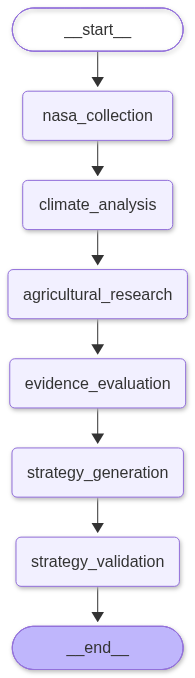

In [14]:
graph = build_graph()
display(Image(graph.get_graph().draw_mermaid_png()))

In [32]:

import json
import traceback

require_api_keys()

print("=" * 65)
print("FIELD SHIFT - ADAPTING FARMS WITH NASA DATA")
print("=" * 65)

print(f"Farm: {FARM_DATA['farmName']}")
print(f"Location: {FARM_DATA['location']}")
print(f"NASA period: {START_DATE} - {END_DATE}")
print(f"Groq model: {GROQ_MODEL}")

graph = build_graph()

initial_state: FieldShiftState = {
    "farm": FARM_DATA,
}

final_state = {}
workflow_completed = False

try:

    print("\nStarting workflow...\n")

    for event in graph.stream(
        initial_state,
        stream_mode="updates"
    ):

        for node_name, node_output in event.items():

            print("\n" + "=" * 65)
            print(f"NODE COMPLETED: {node_name}")
            print("=" * 65)

            print(
                json.dumps(
                    node_output,
                    ensure_ascii=False,
                    indent=2,
                    default=str
                )
            )

            final_state.update(node_output)

    workflow_completed = True

except Exception as exc:

    print("\n" + "!" * 65)
    print("WORKFLOW FAILED")
    print("!" * 65)

    print(f"Error type: {type(exc).__name__}")
    print(f"Error message: {exc}")

    print("\nFull traceback:")
    traceback.print_exc()

    print("\nLast successful outputs:")
    print(
        json.dumps(
            final_state,
            ensure_ascii=False,
            indent=2,
            default=str
        )
    )


# Save available results, even if the workflow failed.
output = {
    "farm": FARM_DATA,
    "climate_summary": final_state.get("climate_summary"),
    "research_results": final_state.get("research_results"),
    "evidence_review": final_state.get("evidence_review"),
    "strategy_output": final_state.get("strategy_output"),
    "validation": final_state.get("validation"),
}

output_path = "field_shift_output.json"

with open(output_path, "w", encoding="utf-8") as file:
    json.dump(
        output,
        file,
        ensure_ascii=False,
        indent=2,
        default=str
    )


if workflow_completed:

    print("\n" + "=" * 65)
    print("PROJECT COMPLETED")
    print("=" * 65)

    strategies = (
        output.get("strategy_output") or {}
    ).get("strategies", [])

    for number, strategy in enumerate(strategies, start=1):
        print(f"\n{number}. {strategy['name']}")
        print("Crops:", " -> ".join(strategy["crop_sequence"]))
        print("Seasons:", " -> ".join(strategy["seasons"]))
        print("Rationale:", strategy["rationale"])

    print("\nValidation:")
    print(
        json.dumps(
            output["validation"],
            ensure_ascii=False,
            indent=2
        )
    )

else:

    print("\nWORKFLOW FAILED - PARTIAL RESULTS SAVED")
    print("The generated strategies are not available yet.")

print(f"\nResults saved to: {output_path}")


FIELD SHIFT - ADAPTING FARMS WITH NASA DATA
Farm: Demo Farm
Location: Damanhur, Beheira, Egypt
NASA period: 20250101 - 20251231
Groq model: openai/gpt-oss-20b

Starting workflow...


[1/6] Downloading historical climate data from NASA POWER...
Downloaded 365 daily records.

NODE COMPLETED: nasa_collection
{
  "climate_data": [
    {
      "date": "2025-01-01",
      "T2M": 14.8,
      "T2M_MAX": 20.73,
      "T2M_MIN": 10.46,
      "PRECTOTCORR": 0.02
    },
    {
      "date": "2025-01-02",
      "T2M": 14.2,
      "T2M_MAX": 20.96,
      "T2M_MIN": 9.77,
      "PRECTOTCORR": 0.01
    },
    {
      "date": "2025-01-03",
      "T2M": 14.44,
      "T2M_MAX": 20.95,
      "T2M_MIN": 9.43,
      "PRECTOTCORR": 0.01
    },
    {
      "date": "2025-01-04",
      "T2M": 14.26,
      "T2M_MAX": 20.33,
      "T2M_MIN": 9.78,
      "PRECTOTCORR": 0.05
    },
    {
      "date": "2025-01-05",
      "T2M": 14.84,
      "T2M_MAX": 20.19,
      "T2M_MIN": 10.17,
      "PRECTOTCORR": 0.18
    },
 

Traceback (most recent call last):
  File "C:\Users\aliaa\AppData\Local\Temp\ipykernel_3456\811774376.py", line 28, in <module>
    for event in graph.stream(
                 ~~~~~~~~~~~~^
        initial_state,
        ^^^^^^^^^^^^^^
        stream_mode="updates"
        ^^^^^^^^^^^^^^^^^^^^^
    ):
    ^
  File "c:\Users\aliaa\Desktop\Adapting-Farms-with-NASA-Data\backend\.venv\Lib\site-packages\langgraph\pregel\main.py", line 3083, in stream
    for _ in runner.tick(
             ~~~~~~~~~~~^
        [t for t in loop.tasks.values() if not t.writes],
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ...<2 lines>...
        schedule_task=loop.accept_push,
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    ):
    ^
  File "c:\Users\aliaa\Desktop\Adapting-Farms-with-NASA-Data\backend\.venv\Lib\site-packages\langgraph\pregel\_runner.py", line 204, in tick
    run_with_retry(
    ~~~~~~~~~~~~~~^
        t,
        ^^
    ...<10 lines>...
        },
        ^^
    )
    ^
  File "c:\

In [45]:
llm = get_llm()

response = llm.invoke(
    'Return only this JSON object: {"status": "ok"}'
)

print("CONTENT:")
print(repr(response.content))

print("\nRESPONSE METADATA:")
print(response.response_metadata)

CONTENT:
'{"status": "ok"}'

RESPONSE METADATA:
{'token_usage': {'completion_tokens': 135, 'prompt_tokens': 83, 'total_tokens': 218, 'completion_time': 0.13928554, 'completion_tokens_details': {'reasoning_tokens': 120}, 'prompt_time': 0.003959305, 'prompt_tokens_details': None, 'queue_time': 0.016375622, 'total_time': 0.143244845}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_9b8528b477', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}


In [44]:
print(repr(response.content))

NameError: name 'response' is not defined